In [3]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier


In [4]:
CSV_PATH = r"C:\Users\ASUS\Downloads\Bank Customer Churn Prediction.csv"  # change path if needed
df = pd.read_csv(CSV_PATH)

df.ffill(inplace=True)  # safe forward-fill
df.head()


,customer_id,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
0,15634602,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,15647311,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,15619304,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,15701354,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,15737888,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [5]:
TARGET_CANDIDATES = ["Churn", "Exited", "Attrition_Flag", "churn", "churn_label"]
target = next((c for c in TARGET_CANDIDATES if c in df.columns), None)

if target is None:
    raise ValueError(f"❌ Could not find a churn column. Columns found:\n{list(df.columns)}")

print("✅ Target Column:", target)

X = df.drop(columns=[target])
y = df[target]

# Convert Yes/No → 1/0 if needed
if y.dtype == object:
    y = y.str.strip().str.lower().map({'yes': 1, 'no': 0, 'true': 1, 'false': 0})
    if y.isna().any():
        y = (pd.factorize(y)[0] > 0).astype(int)


✅ Target Column: churn


In [6]:
num_cols = X.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = X.select_dtypes(exclude=[np.number]).columns.tolist()

print("Numeric Columns:", num_cols)
print("Categorical Columns:", cat_cols)


Numeric Columns: ['customer_id', 'credit_score', 'age', 'tenure', 'balance', 'products_number', 'credit_card', 'active_member', 'estimated_salary']
Categorical Columns: ['country', 'gender']


In [7]:
preprocess = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
    ],
    remainder="drop",
)


In [8]:
lr_pipe = Pipeline([
    ("prep", preprocess),
    ("clf", LogisticRegression(max_iter=1000))
])

rf_pipe = Pipeline([
    ("prep", preprocess),
    ("clf", RandomForestClassifier(n_estimators=300, random_state=42))
])

xgb_pipe = Pipeline([
    ("prep", preprocess),
    ("clf", XGBClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=6,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric="logloss",
        random_state=42
    ))
])


In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)


In [10]:
def evaluate(name, model):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    # If prob available → use for ROC-AUC
    if hasattr(model.named_steps["clf"], "predict_proba"):
        y_proba = model.predict_proba(X_test)[:, 1]
    else:
        y_proba = y_pred

    print(f"\n===== {name} Results =====")
    print(classification_report(y_test, y_pred, digits=4))
    print("ROC-AUC:", round(roc_auc_score(y_test, y_proba), 4))
    print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
    return model


In [11]:
lr_model = evaluate("Logistic Regression", lr_pipe)
rf_model = evaluate("Random Forest", rf_pipe)
xgb_model = evaluate("XGBoost", xgb_pipe)



===== Logistic Regression Results =====
              precision    recall  f1-score   support

           0     0.8243    0.9663    0.8897      1991
           1     0.5964    0.1945    0.2933       509

    accuracy                         0.8092      2500
   macro avg     0.7104    0.5804    0.5915      2500
weighted avg     0.7779    0.8092    0.7683      2500

ROC-AUC: 0.7835
Confusion Matrix:
 [[1924   67]
 [ 410   99]]

===== Random Forest Results =====
              precision    recall  f1-score   support

           0     0.8808    0.9684    0.9225      1991
           1     0.7974    0.4872    0.6049       509

    accuracy                         0.8704      2500
   macro avg     0.8391    0.7278    0.7637      2500
weighted avg     0.8638    0.8704    0.8578      2500

ROC-AUC: 0.8632
Confusion Matrix:
 [[1928   63]
 [ 261  248]]

===== XGBoost Results =====
              precision    recall  f1-score   support

           0     0.8819    0.9563    0.9176      1991
        

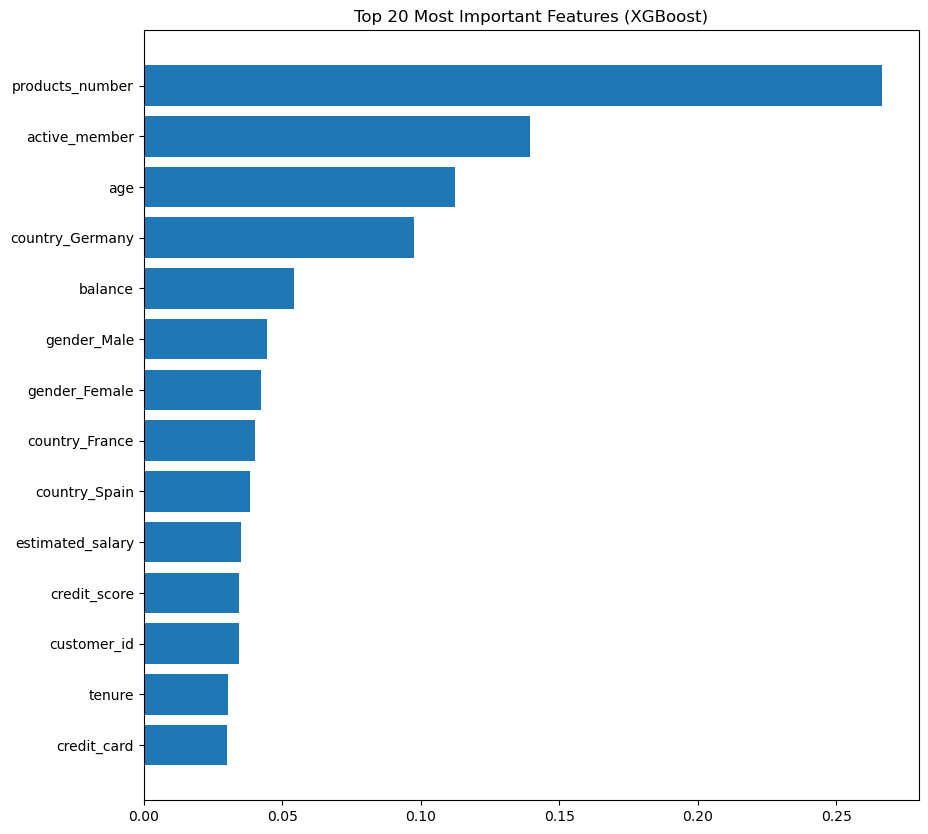

In [12]:
import matplotlib.pyplot as plt

def get_feature_names(ct):
    names = []
    for name, transformer, cols in ct.transformers_:
        if name == "num":
            names.extend(cols)
        elif name == "cat":
            names.extend(transformer.get_feature_names_out(cols))
    return names

feat_names = get_feature_names(xgb_model.named_steps["prep"])
importances = xgb_model.named_steps["clf"].feature_importances_
order = np.argsort(importances)

plt.figure(figsize=(10, 10))
plt.barh(np.array(feat_names)[order][-20:], importances[order][-20:])
plt.title("Top 20 Most Important Features (XGBoost)")
plt.show()


In [13]:
example = {c: (0 if c in num_cols else "Unknown") for c in X.columns}

example.update({
    "Age": 40,
    "Balance": 50000,
    "NumOfProducts": 2,
    "IsActiveMember": 1,
    "EstimatedSalary": 70000
})

new_customer = pd.DataFrame([example], columns=X.columns)

pred = xgb_model.predict(new_customer)[0]

print("Prediction:", "🚨 Likely to Leave" if pred == 1 else "✅ Likely to Stay")


Prediction: ✅ Likely to Stay
